# 01 — Price panel

Build the daily price used by every later notebook.

**Price.** For each card, billing plan, and date, take each provider's median `hourly_per_gpu`, then the median across providers. A provider with many listings has the same vote as a provider with one. Quotes that are missing or not positive are ignored.

**Also stored.** `avg_price` from the summary file, on those same dates, so the median can be compared with the published average. The indices use `price`, the provider median.

**Baseline.** `GPU_BASE_PLAN` in `.env` (currently the Nvidia H100 on-demand plan). This panel does not depend on that choice. It is stored once under `outputs/shared/panel/`. Switching the baseline does not rebuild it. A later run rewrites a series only when that series' source file changed.

The raw files live in `data/parts/`. Dates missing there stay missing here; nothing is interpolated.


In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from icx.config import load_baseline
from icx.panel import sync_price_panel
from icx.runtime import require_project_venv
from icx.store import Decision, open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
baseline = load_baseline(ROOT)

print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {baseline.key}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND


In [2]:
built = sync_price_panel(layout)
panel = built.frame
print(f"Build:         {built.decision.value}")
print(f"Rows upserted: {built.rows_upserted}")
print(f"Panel rows:    {len(panel):,}")
print(f"Series:        {panel['series'].nunique():,}")
print(f"Dates:         {panel['date'].nunique():,}")

again = sync_price_panel(layout)
print(f"Second build:  {again.decision.value}")
if again.decision is not Decision.SKIP:
    raise RuntimeError("Unchanged source files should reuse the stored panel.")

if panel.duplicated(["date", "series"]).any():
    raise RuntimeError("Panel has duplicate date/series rows.")
if (panel["price"] <= 0).any():
    raise RuntimeError("Panel contains a non-positive price.")


Build:         skip
Rows upserted: 0
Panel rows:    28,893
Series:        274
Dates:         133
Second build:  skip


In [3]:
base = panel.loc[panel["series"] == baseline.key].sort_values("date").copy()
if base.empty:
    raise RuntimeError(f"{baseline.key} has no provider median in the panel.")

observed = pd.to_datetime(sorted(panel["date"].unique()))
calendar = pd.date_range(observed.min(), observed.max(), freq="D")
missing = calendar.difference(observed)
print(f"Observed: {observed.min().date()} → {observed.max().date()} ({len(observed)} dates)")
print(f"Calendar days with no quotes at all: {len(missing)}")
if len(missing):
    print(f"Missing span: {missing.min().date()} → {missing.max().date()}")

print()
print(f"{baseline.key}")
print(base[["date", "price", "n_providers", "avg_price"]].describe().to_string())
print()
print(base[["date", "price", "n_providers", "avg_price"]].head(3).to_string(index=False))
print("...")
print(base[["date", "price", "n_providers", "avg_price"]].tail(3).to_string(index=False))

coverage = panel.groupby("series").size()
print()
print("Dates per series")
print(coverage.describe().to_string())


Observed: 2026-04-01 → 2026-09-25 (133 dates)
Calendar days with no quotes at all: 45
Missing span: 2026-04-02 → 2026-05-16

nvidia-h100__ON_DEMAND
            price  n_providers   avg_price
count  133.000000   133.000000  133.000000
mean     3.089097    41.368421    3.774892
std      0.141021     2.770170    0.154186
min      2.790000    36.000000    3.457400
25%      2.960000    40.000000    3.635300
50%      3.076900    41.000000    3.795800
75%      3.225000    44.000000    3.882100
max      3.337500    49.000000    4.148100

      date  price  n_providers  avg_price
2026-04-01  2.855           36     3.4588
2026-05-17  2.930           37     4.1481
2026-05-18  2.930           37     4.1321
...
      date  price  n_providers  avg_price
2026-09-23   3.20           49     3.6645
2026-09-24   3.20           49     3.6493
2026-09-25   3.25           49     3.6425

Dates per series
count    274.000000
mean     105.448905
std       41.955400
min        1.000000
25%       86.000000
50%   

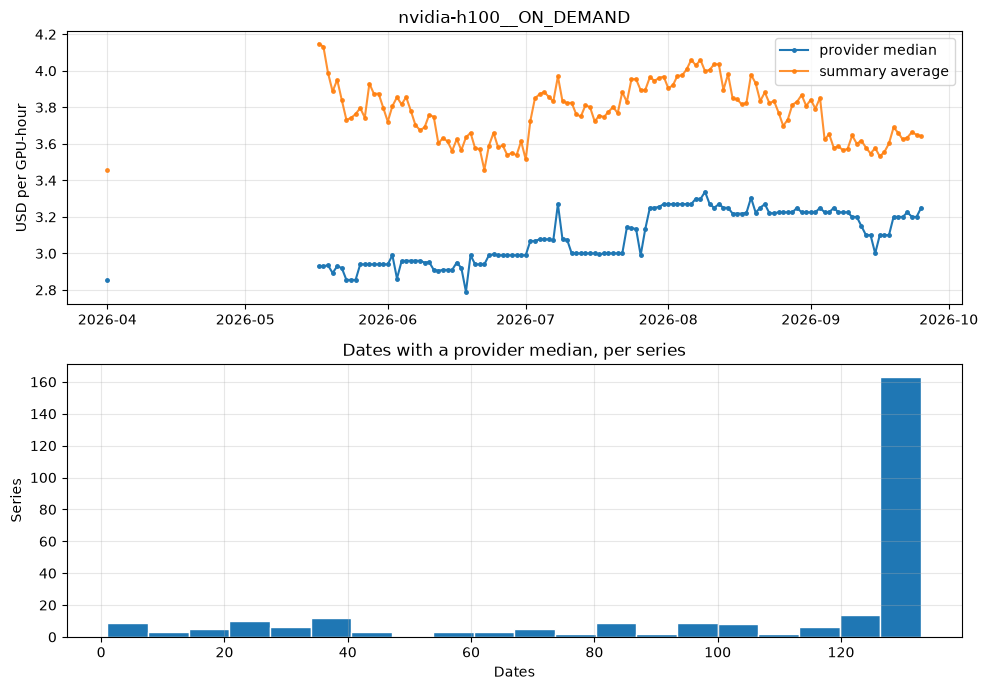

In [4]:
import numpy as np

def with_gaps(frame: pd.DataFrame) -> pd.DataFrame:
    """Insert a missing point wherever successive observations are not adjacent days."""
    ordered = frame.sort_values("date").copy()
    ordered["date"] = pd.to_datetime(ordered["date"])
    rows = []
    previous = None
    for row in ordered.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "price": np.nan, "avg_price": np.nan})
        rows.append({"date": row.date, "price": row.price, "avg_price": row.avg_price})
        previous = row.date
    return pd.DataFrame(rows)

plotted = with_gaps(base)
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(plotted["date"], plotted["price"], label="provider median", color="tab:blue", marker="o", ms=2.5)
axes[0].plot(plotted["date"], plotted["avg_price"], label="summary average", color="tab:orange", alpha=0.85, marker="o", ms=2.5)
axes[0].set_title(baseline.key)
axes[0].set_ylabel("USD per GPU-hour")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(coverage, bins=20, color="tab:blue", edgecolor="white")
axes[1].set_title("Dates with a provider median, per series")
axes[1].set_xlabel("Dates")
axes[1].set_ylabel("Series")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()
